# Semana 2 · Aprendizaje supervisado
## ¿Qué distritos de la costa norte tendrán emergencias por lluvias en la temporada?

**Curso:** IS281 Analítica de datos y sistemas predictivos (UPC) · **Librería:** scikit-learn

Este notebook entrena clasificadores que, para cada distrito y temporada de lluvias (enero a mayo),
estiman la probabilidad de que el distrito tenga emergencias con damnificados. Es la parte **"dónde"**
del sistema predictivo: el resultado final será un mapa de riesgo para 2027.

**Datos:** `datos/2_limpios/modelo/panel_distrito_temporada_1970_2025.csv` (364 distritos × 56 temporadas).
Su diccionario está en `datos/CATALOGO_DATOS.md`.

**Regla principal:** se valida como se usaría en la realidad. Para predecir un año, el modelo se entrena
**solo con los años anteriores**. Se prueba con los tres Niños más dañinos con datos: 1998, 2017 y 2023.

Contenido:
1. La variable objetivo
2. Las variables (qué se sabe antes y qué durante la temporada)
3. Cómo se valida y con qué métricas
4. Los modelos
5. Resultados de la validación
6. ¿Qué variables pesan más?
7. Mapa de 2023: real contra predicho
8. Conclusiones

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import shape
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Carpeta del proyecto (funciona si abres el notebook desde notebooks/ o desde la raíz)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "2_limpios").exists())
LIMPIOS = RAIZ / "datos" / "2_limpios"
SEMILLA = 42
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(LIMPIOS / "modelo" / "panel_distrito_temporada_1970_2025.csv", dtype={"ubigeo": str})
print(f"{len(df):,} filas × {df.shape[1]} columnas | {df.ubigeo.nunique()} distritos | temporadas {df.anio.min()}-{df.anio.max()}")
df.head(3)

20,384 filas × 50 columnas | 364 distritos | temporadas 1970-2025


,ubigeo,distrito,provincia,departamento,anio,fuente_objetivo,emergencias_lluvias,emerg_con_damnificados,damnificados,fallecidos,...,lon_centroide,elev_media_m,elev_min_m,elev_p10_m,pct_area_bajo_50m,pct_area_bajo_200m,pendiente_media_grados,pct_area_pendiente_menor_2,dist_centroide_a_rio_mayor_km,cuenca_max_que_cruza_km2
0,020101,HUARAZ,HUARAZ,ANCASH,1970,DesInventar,3,0,0,0,...,-77.4749,4131.0,3031.4,3422.7,0.0,0.0,19.33,0.6,4.73,1977.1
1,020101,HUARAZ,HUARAZ,ANCASH,1971,DesInventar,0,0,0,0,...,-77.4749,4131.0,3031.4,3422.7,0.0,0.0,19.33,0.6,4.73,1977.1
2,020101,HUARAZ,HUARAZ,ANCASH,1972,DesInventar,7,0,0,0,...,-77.4749,4131.0,3031.4,3422.7,0.0,0.0,19.33,0.6,4.73,1977.1


## 1. La variable objetivo

La tabla trae `tuvo_damnificados`: 1 si el distrito tuvo al menos una emergencia por lluvias con
damnificados entre enero y mayo. El problema es que en un Niño fuerte **casi todos** los distritos
tienen algún damnificado (66 % en 2017 y 75 % en 2023), así que esa variable no separa bien las
zonas de **alta incidencia**, que es lo que pide el proyecto.

Por eso se prueba una segunda variable objetivo:

- `alta_incidencia` = 1 si el distrito tuvo **100 damnificados o más** en la temporada.

El umbral de 100 es una decisión del proyecto: puedes cambiarlo en `UMBRAL_ALTA`.

**Ojo con la fuente.** Hasta 2002 la variable sale de DesInventar y desde 2003 de INDECI, que registra
muchos más eventos. El salto de 2003 no es climático: por eso se agrega `es_indeci` como variable.

% de filas con 1, por fuente:
                 tuvo_damnificados  alta_incidencia
fuente_objetivo                                    
DesInventar                    2.2              1.3
INDECI                        19.1              6.4


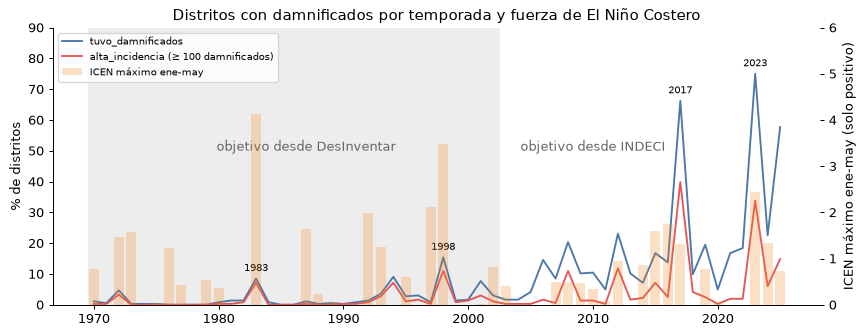

In [2]:
UMBRAL_ALTA = 100
df["alta_incidencia"] = (df.damnificados >= UMBRAL_ALTA).astype(int)
df["es_indeci"] = (df.fuente_objetivo == "INDECI").astype(int)
for d in ["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD"]:  # Áncash queda como referencia
    df["dep_" + d.lower().replace(" ", "_")] = (df.departamento == d).astype(int)

OBJETIVOS = ["tuvo_damnificados", "alta_incidencia"]
print("% de filas con 1, por fuente:")
print((df.groupby("fuente_objetivo")[OBJETIVOS].mean() * 100).round(1))

por_anio = df.groupby("anio").agg(tuvo_damnificados=("tuvo_damnificados", "mean"),
                                   alta_incidencia=("alta_incidencia", "mean"),
                                   icen_max_ene_may=("icen_max_ene_may", "first"))
fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(1969.5, 2002.5, color="0.93")
ax.text(1987, 50, "objetivo desde DesInventar", ha="center", color="0.4")
ax.text(2010, 50, "objetivo desde INDECI", ha="center", color="0.4")
ax.plot(por_anio.index, 100 * por_anio.tuvo_damnificados, label="tuvo_damnificados", color="#4C78A8")
ax.plot(por_anio.index, 100 * por_anio.alta_incidencia, label=f"alta_incidencia (≥ {UMBRAL_ALTA} damnificados)", color="#E45756")
ax.set_ylabel("% de distritos")
ax.set_ylim(0, 90)
ax2 = ax.twinx()
ax2.bar(por_anio.index, por_anio.icen_max_ene_may.clip(lower=0), color="#F58518", alpha=0.25, label="ICEN máximo ene-may")
ax2.set_ylabel("ICEN máximo ene-may (solo positivo)")
ax2.set_ylim(0, 6)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax.set_title("Distritos con damnificados por temporada y fuerza de El Niño Costero")
for a in [1983, 1998, 2017, 2023]:
    ax.annotate(str(a), (a, 100 * por_anio.loc[a, "tuvo_damnificados"]), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
plt.show()

## 2. Las variables

Se arman dos conjuntos, según **cuándo** se conoce cada dato. Es lo mismo que separa tus modelos A y B
por departamento:

- **`ANTES`** (pronóstico real): lo que se sabe al empezar la temporada.
  - el ICEN y el Niño 3.4 hasta noviembre del año anterior;
  - la lluvia de noviembre y diciembre;
  - el historial del distrito en temporadas anteriores;
  - los atributos fijos: relieve, ríos, población, pobreza y departamento.
- **`ESCENARIO`**: lo anterior más lo que pasa **durante** la temporada: el ICEN de enero a mayo y la lluvia
  relativa a lo normal. Responde "¿qué distritos se dañan **si** llueve como en 2017?". No es un pronóstico,
  porque esa lluvia no se conoce de antemano.

No se usan las columnas de historial de `distritos_costa_norte_atributos.csv` (por ejemplo, damnificados en
2017), porque mirarían el futuro.

In [3]:
FIJOS = ["superficie_km2", "poblacion_2020_estimada", "pob_densidad_2020", "idh_2019", "pct_pobreza_total",
         "pct_pobreza_extrema", "indice_vulnerabilidad_alimentaria", "altitud_capital_m", "lat_centroide",
         "lon_centroide", "elev_media_m", "elev_min_m", "elev_p10_m", "pct_area_bajo_50m", "pct_area_bajo_200m",
         "pendiente_media_grados", "pct_area_pendiente_menor_2", "dist_centroide_a_rio_mayor_km",
         "cuenca_max_que_cruza_km2", "dep_tumbes", "dep_piura", "dep_lambayeque", "dep_la_libertad"]
ANTES = ["icen_nov_previo", "icen_max_jun_nov_previo", "icen_cambio_ago_nov_previo", "nino34_anom_nov_previo",
         "lluvia_nov_dic_previo_pisco_reciente_mm", "hist_tuvo_damnificados_temporada_anterior",
         "hist_temporadas_con_damnificados", "hist_pct_temporadas_con_damnificados", "es_indeci"] + FIJOS
ESCENARIO = ANTES + ["icen_max_ene_may", "icen_medio_ene_may", "lluvia_ene_may_pisco_reciente_relativa",
                     "lluvia_ene_may_chirps_relativa", "lluvia_mes_max_ene_may_pisco_reciente_mm"]
CONJUNTOS = {"antes": ANTES, "escenario": ESCENARIO}
print(f"ANTES: {len(ANTES)} variables | ESCENARIO: {len(ESCENARIO)} variables")
print("Vacíos en ESCENARIO (se imputan con la mediana o los maneja el modelo):")
print((df[ESCENARIO].isna().mean() * 100).round(1).loc[lambda s: s > 0].to_string())

ANTES: 32 variables | ESCENARIO: 37 variables
Vacíos en ESCENARIO (se imputan con la mediana o los maneja el modelo):
lluvia_nov_dic_previo_pisco_reciente_mm      21.4
hist_tuvo_damnificados_temporada_anterior     1.8
hist_temporadas_con_damnificados              1.8
hist_pct_temporadas_con_damnificados          1.8
lluvia_ene_may_pisco_reciente_relativa       19.6
lluvia_ene_may_chirps_relativa               19.6
lluvia_mes_max_ene_may_pisco_reciente_mm     19.6


## 3. Cómo se valida

- **Validación temporal:** para probar el año *t*, se entrena con todas las temporadas **anteriores** a *t* y
  se predice *t*. Nunca se mezclan años al azar: si el modelo viera 2017 al entrenar, el resultado de 2017
  sería engañoso.
- **Años de prueba:** 1998 (Niño extraordinario, DesInventar), 2017 (Niño costero) y 2023 (ciclón Yaku y
  Niño costero), los dos con INDECI.

**Métricas.** No se usa *accuracy*: con pocos positivos, un modelo que dice "nunca pasa nada" tendría
buena accuracy y no serviría. Se usan:

| Métrica | Qué mide | Azar |
|---|---|---|
| **ROC-AUC** | Si ordena bien: probabilidad de que un distrito dañado quede por encima de uno no dañado | 0,5 |
| **PR-AUC** | Precisión promedio sobre todos los cortes; castiga los falsos positivos | la tasa real |
| **Acierto en el top 50** | De los 50 distritos con mayor probabilidad, % que de verdad tuvo el evento | la tasa real |

Para un mapa de zonas de riesgo, lo que importa es el **orden** (qué distritos van primero), por eso la
métrica principal es ROC-AUC.

In [4]:
ANIOS_PRUEBA = [1998, 2017, 2023]


def separar(anio_prueba):
    """Entrena con las temporadas anteriores; prueba con la del año."""
    return df[df.anio < anio_prueba], df[df.anio == anio_prueba]


def evaluar(y, prob, k=50):
    top = np.argsort(-prob)[:k]
    return {"roc_auc": roc_auc_score(y, prob), "pr_auc": average_precision_score(y, prob),
            "acierto_top50": y[top].mean(), "tasa_real": y.mean(), "prob_media_predicha": prob.mean()}

## 4. Los modelos

| Modelo | Idea | Preparación |
|---|---|---|
| **Línea base: historial** | El distrito que más veces se dañó antes, se dañará de nuevo. Su "probabilidad" es el % de temporadas anteriores con damnificados | ninguna |
| **Regresión logística** | Lineal; fácil de explicar | imputar vacíos y estandarizar |
| **Random Forest** | Muchos árboles en votación; capta interacciones (por ejemplo, ICEN alto *y* zona baja) | imputar vacíos |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Árboles en secuencia, cada uno corrige al anterior; maneja vacíos solo | ninguna |

Los tres usan `class_weight="balanced"` para que los pocos positivos pesen lo mismo que los muchos negativos.
Cualquier modelo tiene que ganarle a la línea base para valer la pena.

In [5]:
def modelos():
    return {
        "Regresión logística": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                             LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                              class_weight="balanced_subsample",
                                                              n_jobs=-1, random_state=SEMILLA)),
        "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                            class_weight="balanced", random_state=SEMILLA),
    }


filas = []
for objetivo in OBJETIVOS:
    for anio in ANIOS_PRUEBA:
        entreno, prueba = separar(anio)
        y = prueba[objetivo].to_numpy()
        base = prueba.hist_pct_temporadas_con_damnificados.fillna(0).to_numpy() / 100  # de % a 0-1
        filas.append({"objetivo": objetivo, "anio": anio, "conjunto": "antes", "modelo": "Línea base: historial",
                      **evaluar(y, base)})
        for conjunto, cols in CONJUNTOS.items():
            for nombre, m in modelos().items():
                m.fit(entreno[cols], entreno[objetivo])
                prob = m.predict_proba(prueba[cols])[:, 1]
                filas.append({"objetivo": objetivo, "anio": anio, "conjunto": conjunto, "modelo": nombre,
                              **evaluar(y, prob)})

resultados = pd.DataFrame(filas).round(3)
(RAIZ / "resultados").mkdir(exist_ok=True)
resultados.to_csv(RAIZ / "resultados" / "semana2_validacion_distritos.csv", index=False)
print("Guardado en resultados/semana2_validacion_distritos.csv")

Guardado en resultados/semana2_validacion_distritos.csv


## 5. Resultados de la validación

ROC-AUC de cada modelo en cada año de prueba (más alto es mejor; 0,5 es azar). La fila de la línea base
se repite como referencia en los dos conjuntos.

In [6]:
orden = ["Línea base: historial", "Regresión logística", "Random Forest", "Gradient Boosting"]
base = resultados[resultados.modelo == orden[0]]
tabla = pd.concat([resultados, base.assign(conjunto="escenario")])
for objetivo in OBJETIVOS:
    t = (tabla[tabla.objetivo == objetivo]
         .pivot_table(index=["conjunto", "modelo"], columns="anio", values="roc_auc")
         .reindex(orden, level="modelo"))
    t["promedio"] = t.mean(axis=1)
    print(f"\nROC-AUC · objetivo = {objetivo}")
    display(t.round(3))


ROC-AUC · objetivo = tuvo_damnificados


anio                              1998   2017   2023  promedio
conjunto  modelo                                              
antes     Línea base: historial  0.681  0.640  0.682     0.668
          Regresión logística    0.585  0.631  0.688     0.635
          Random Forest          0.742  0.634  0.697     0.691
          Gradient Boosting      0.693  0.640  0.756     0.696
escenario Línea base: historial  0.681  0.640  0.682     0.668
          Regresión logística    0.639  0.682  0.755     0.692
          Random Forest          0.726  0.704  0.798     0.743
          Gradient Boosting      0.664  0.662  0.767     0.698


ROC-AUC · objetivo = alta_incidencia


anio                              1998   2017   2023  promedio
conjunto  modelo                                              
antes     Línea base: historial  0.649  0.666  0.693     0.669
          Regresión logística    0.587  0.675  0.762     0.675
          Random Forest          0.697  0.632  0.817     0.715
          Gradient Boosting      0.667  0.650  0.806     0.708
escenario Línea base: historial  0.649  0.666  0.693     0.669
          Regresión logística    0.676  0.731  0.824     0.744
          Random Forest          0.689  0.770  0.865     0.775
          Gradient Boosting      0.601  0.771  0.849     0.740

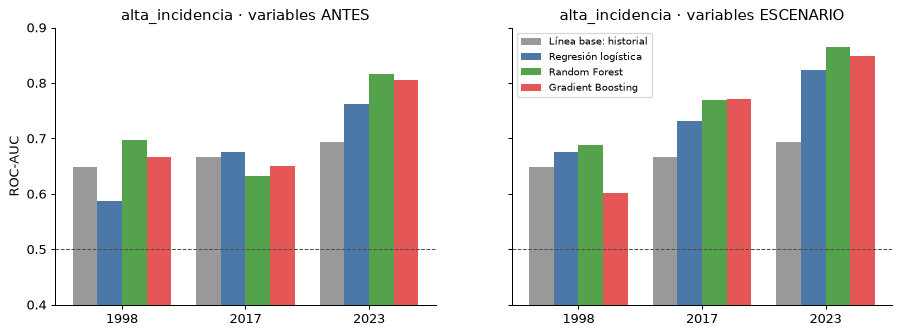

Detalle de alta_incidencia, variables ESCENARIO:


roc_auc  pr_auc  acierto_top50  tasa_real  \
anio modelo                                                             
1998 Gradient Boosting        0.601   0.141           0.14      0.110   
     Línea base: historial    0.649   0.191           0.22      0.110   
     Random Forest            0.689   0.277           0.26      0.110   
     Regresión logística      0.676   0.280           0.24      0.110   
2017 Gradient Boosting        0.771   0.735           0.84      0.398   
     Línea base: historial    0.666   0.551           0.60      0.398   
     Random Forest            0.770   0.719           0.82      0.398   
     Regresión logística      0.731   0.674           0.74      0.398   
2023 Gradient Boosting        0.849   0.743           0.84      0.338   
     Línea base: historial    0.693   0.533           0.60      0.338   
     Random Forest            0.865   0.798           0.88      0.338   
     Regresión logística      0.824   0.710           0.78      0.338   

                            prob_media_predicha  
anio modelo                                      
1998 Gradient Boosting                    0.671  
     Línea base: historial                0.016  
     Random Forest                        0.162  
     Regresión logística                  0.800  
2017 Gradient Boosting                    0.480  
     Línea base: historial                0.047  
     Random Forest                        0.136  
     Regresión logística                  0.703  
2023 Gradient Boosting                    0.627  
     Línea base: historial                0.067  
     Random Forest                        0.295  
     Regresión logística                  0.838

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
colores = dict(zip(orden, ["0.6", "#4C78A8", "#54A24B", "#E45756"]))
for ax, conjunto in zip(ejes, ["antes", "escenario"]):
    t = tabla[(tabla.objetivo == "alta_incidencia") & (tabla.conjunto == conjunto)]
    for i, modelo in enumerate(orden):
        v = t[t.modelo == modelo].set_index("anio").roc_auc.reindex(ANIOS_PRUEBA)
        ax.bar(np.arange(3) + (i - 1.5) * 0.2, v, width=0.2, color=colores[modelo], label=modelo)
    ax.axhline(0.5, color="0.3", lw=0.8, ls="--")
    ax.set_xticks(range(3), ANIOS_PRUEBA)
    ax.set_ylim(0.4, 0.9)
    ax.set_title(f"alta_incidencia · variables {conjunto.upper()}")
ejes[0].set_ylabel("ROC-AUC")
ejes[1].legend(loc="upper left", fontsize=8)
fig.savefig(RAIZ / "resultados" / "figuras" / "semana2_validacion_roc_auc.png", dpi=120, bbox_inches="tight")
plt.show()

print("Detalle de alta_incidencia, variables ESCENARIO:")
display(resultados[(resultados.objetivo == "alta_incidencia") & ((resultados.conjunto == "escenario") | (resultados.modelo == orden[0]))]
        .sort_values(["anio", "modelo"]).set_index(["anio", "modelo"]).drop(columns=["objetivo", "conjunto"]))

## 6. ¿Qué variables pesan más?

Se usa la **importancia por permutación**: se desordena una variable en los datos de prueba y se mide
cuánto empeora el ROC-AUC. Si empeora mucho, el modelo depende de esa variable. Se calcula para el
Random Forest con variables ESCENARIO, objetivo `alta_incidencia`, entrenado hasta 2022 y probado en 2023.

**Ojo:** el ICEN y el Niño 3.4 valen lo mismo para todos los distritos de un año, así que desordenarlos
dentro de 2023 no cambia nada y su importancia sale cero. Eso no quiere decir que no sirvan: su trabajo es
separar años fuertes de años normales cuando el modelo aprende, y eso no se ve probando un solo año.

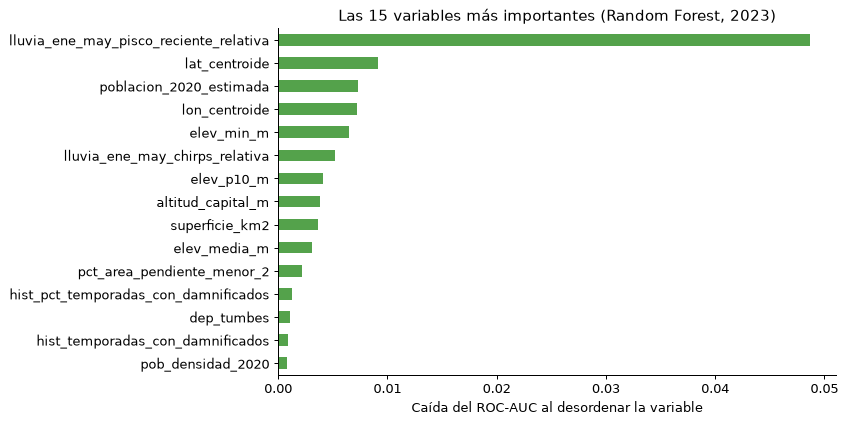

In [8]:
entreno, prueba = separar(2023)
rf = modelos()["Random Forest"].fit(entreno[ESCENARIO], entreno["alta_incidencia"])
imp = permutation_importance(rf, prueba[ESCENARIO], prueba["alta_incidencia"], scoring="roc_auc",
                             n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=ESCENARIO).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
importancia.tail(15).plot.barh(ax=ax, color="#54A24B")
ax.set_xlabel("Caída del ROC-AUC al desordenar la variable")
ax.set_title("Las 15 variables más importantes (Random Forest, 2023)")
plt.show()

## 7. Mapa de 2023: real contra predicho

A la izquierda, los distritos que de verdad tuvieron alta incidencia en 2023. A la derecha, la probabilidad
que les dio el Random Forest (variables ESCENARIO), entrenado solo con 1970-2022.

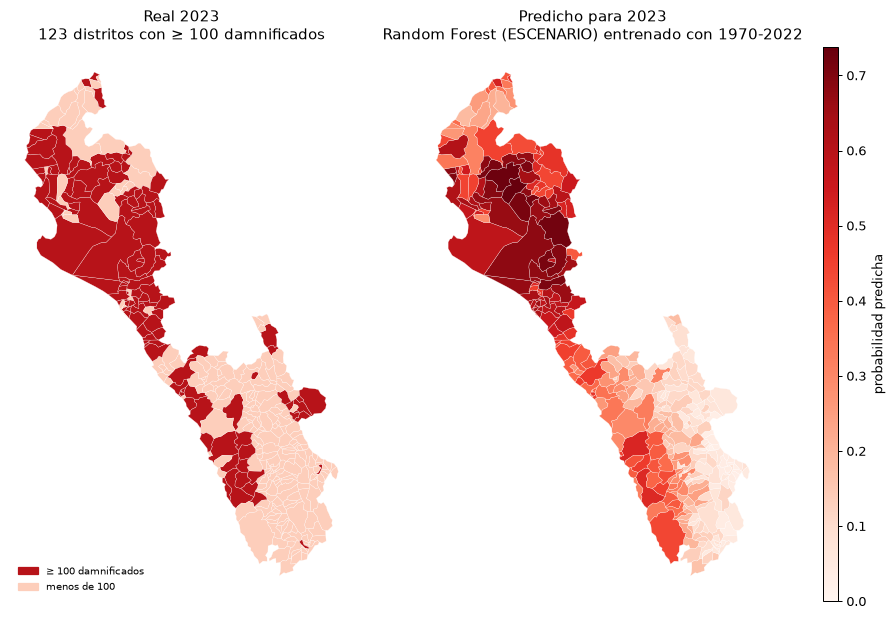

Los 15 distritos con mayor probabilidad en 2023 y lo que pasó:


,distrito,provincia,departamento,prob,damnificados,alta_incidencia
17637,CHULUCANAS,MORROPON,PIURA,0.738,426,1
16573,TAMBO GRANDE,PIURA,PIURA,0.728,2965,1
17357,HUARMACA,HUANCABAMBA,PIURA,0.720,2230,1
17693,BUENOS AIRES,MORROPON,PIURA,0.716,485,1
15789,MOTUPE,LAMBAYEQUE,LAMBAYEQUE,0.712,969,1
17805,LA MATANZA,MORROPON,PIURA,0.711,82,0
18589,SULLANA,SULLANA,PIURA,0.707,1528,1
15341,PITIPO,FERREÑAFE,LAMBAYEQUE,0.704,1599,1
17021,SAPILLICA,AYABACA,PIURA,0.704,179,1
18365,COLAN,PAITA,PIURA,0.698,586,1


In [9]:
gj = json.loads((LIMPIOS / "territorio" / "distritos_costa_norte.geojson").read_text())
geoms = {f["properties"]["ubigeo"]: shape(f["geometry"]) for f in gj["features"]}
prueba = prueba.assign(prob=rf.predict_proba(prueba[ESCENARIO])[:, 1])


def dibujar(ax, valores, cmap, vmin, vmax):
    mapa = plt.get_cmap(cmap)
    for ubigeo, g in geoms.items():
        v = valores.get(ubigeo, np.nan)
        color = mapa((v - vmin) / (vmax - vmin)) if pd.notna(v) else "0.9"
        for parte in getattr(g, "geoms", [g]):
            x, y = parte.exterior.xy
            ax.fill(x, y, color=color, ec="white", lw=0.2)
    ax.set_aspect("equal")
    ax.axis("off")


from matplotlib.patches import Patch

fig, ejes = plt.subplots(1, 3, figsize=(12, 8), gridspec_kw={"width_ratios": [1, 1, 0.04]})
real = prueba.set_index("ubigeo")["alta_incidencia"]
dibujar(ejes[0], real.to_dict(), "Reds", -0.3, 1.3)
ejes[0].set_title(f"Real 2023\n{real.sum()} distritos con ≥ {UMBRAL_ALTA} damnificados")
ejes[0].legend(handles=[Patch(color=plt.get_cmap("Reds")(1.3 / 1.6), label=f"≥ {UMBRAL_ALTA} damnificados"),
                        Patch(color=plt.get_cmap("Reds")(0.3 / 1.6), label=f"menos de {UMBRAL_ALTA}")],
               loc="lower left", fontsize=8, frameon=False)
prob = prueba.set_index("ubigeo")["prob"]
dibujar(ejes[1], prob.to_dict(), "Reds", 0, prob.max())
ejes[1].set_title("Predicho para 2023\nRandom Forest (ESCENARIO) entrenado con 1970-2022")
fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, prob.max())), cax=ejes[2],
             label="probabilidad predicha")
fig.savefig(RAIZ / "resultados" / "figuras" / "semana2_mapa_2023_real_vs_predicho.png", dpi=120, bbox_inches="tight")
plt.show()

top = prueba.sort_values("prob", ascending=False).head(15)
print("Los 15 distritos con mayor probabilidad en 2023 y lo que pasó:")
display(top[["distrito", "provincia", "departamento", "prob", "damnificados", "alta_incidencia"]].round(3))

## 8. Conclusiones

Todo lo de abajo sale de la validación temporal: cada año se predijo entrenando solo con los anteriores.

**1. El modelo sí encuentra los distritos de alta incidencia cuando se conoce la lluvia.**
El mejor es Random Forest con variables ESCENARIO y objetivo `alta_incidencia`. Su ROC-AUC fue 0,770 en 2017 y
0,865 en 2023; la línea base del historial sacó 0,666 y 0,693. En 2023, de los 50 distritos que puso primero,
44 (88 %) tuvieron 100 damnificados o más, cuando solo el 34 % de los distritos llegó a esa cifra.

**2. Con lo que se sabe antes de la temporada, la mejora es menor.**
Con las variables ANTES, el Random Forest sacó 0,697 en 1998, 0,632 en 2017 y 0,817 en 2023. Le ganó a la línea
base en 1998 y 2023, pero no en 2017. Tiene sentido: el ICEN de noviembre valía 4,08 antes de 1998 (el Niño ya
estaba en marcha), 0,25 antes de 2017 y −1,10 antes de 2023. Los Niños costeros de 2017 y 2023 aparecieron
recién en enero-marzo, así que en noviembre no había forma de verlos venir.

**3. La lluvia de la temporada es lo que más pesa.**
Desordenar `lluvia_ene_may_pisco_reciente_relativa` baja el ROC-AUC de 2023 en casi 0,05, cinco veces más que
cualquier otra variable. Después vienen la ubicación (latitud y longitud), la población y las zonas bajas
(elevación mínima). Para 2027, entonces, el sistema conviene presentarlo como **escenarios**:
"si llueve como en 1998, 2017 o 2023, estos son los distritos de mayor riesgo".

**4. `alta_incidencia` es mejor objetivo que `tuvo_damnificados`.**
En 2017 y 2023 entre el 66 % y el 75 % de los distritos tuvo algún damnificado, así que "tuvo daño o no" casi no
separa zonas. Con el mismo modelo, el promedio de ROC-AUC sube de 0,743 a 0,775 al cambiar de objetivo.

**5. Los árboles le ganan a la regresión logística.**
Con variables ESCENARIO, el promedio fue 0,775 para Random Forest, 0,740 para Gradient Boosting y 0,744 para
la regresión logística. Los árboles captan combinaciones como "mucha lluvia **y** zona baja", que un modelo
lineal no ve.

**6. 1998 es el año más difícil.**
Para probarlo solo hay datos de DesInventar de 1970-1997, donde apenas el 1,3 % de las filas son de alta
incidencia. El mejor ROC-AUC fue 0,697 (Random Forest con ANTES) y Gradient Boosting con ESCENARIO (0,601)
quedó por debajo de la línea base (0,649).

**7. Las probabilidades sirven para ordenar, no como porcentaje.**
En 2017 el Random Forest dio en promedio 0,14 de probabilidad cuando la tasa real fue 0,40; la regresión
logística dio 0,70. Los dos ordenan bien, pero sus valores no son probabilidades reales (influyen
`class_weight="balanced"` y el cambio de fuente en 2003). Por eso el mapa de riesgo debe mostrar **niveles por
orden** (por ejemplo, el 20 % de distritos con mayor puntaje = riesgo muy alto) y no "70 % de probabilidad".

**Límites que conviene decir en la exposición**
- Solo hay tres años de prueba: diferencias de ±0,02 en ROC-AUC no son concluyentes.
- La variable objetivo cambia de fuente en 2003. `es_indeci` corrige el nivel, pero no del todo.
- No hay lluvia por distrito antes de 1981; en 1970-1980 esas columnas se rellenan con la mediana.
- Los hiperparámetros todavía no se ajustaron.

## 9. Próximos pasos

- **Semana 2:** la parte "cuánto": conteos de emergencias por departamento con `PoissonRegressor` y
  `HistGradientBoostingRegressor(loss="poisson")`, comparados con tu modelo binomial negativo actual.
- **Ajuste fino:** probar `UMBRAL_ALTA` (50, 100, 200) e hiperparámetros, siempre con validación temporal.
- **Semanas 3-4:** K-means y PCA para agrupar distritos por perfil y encontrar los años más parecidos a
  2027. Eso ayuda a elegir el escenario de lluvia.
- **Semanas 5-6:** una red MLP en Keras sobre esta misma tabla, para compararla con el Random Forest.
- **Semana 7:** el mapa de riesgo 2027 con el Random Forest ESCENARIO bajo los escenarios de lluvia elegidos.
